In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 486kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.07MB/s]


Training images: 60000
Image batch shape: torch.Size([128, 1, 28, 28])
Pixel range: -1.0 to 1.0
Example label: 1


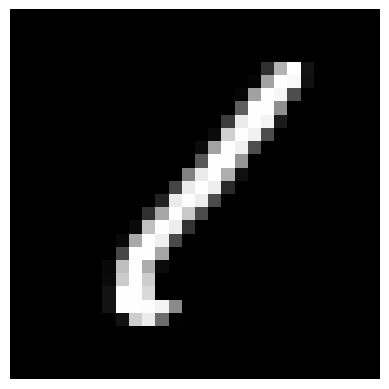

In [2]:
batch_size = 128

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Image batch shape:", images.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())
print("Example label:", labels[0].item())

plt.imshow(images[0].squeeze(), cmap="gray")
plt.axis("off")
plt.show()

In [3]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(100, 7 * 7 * 128)
        self.deconv1 = nn.ConvTranspose2d(
            128, 64, kernel_size=4, stride=2, padding=1
        )
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.deconv2 = nn.ConvTranspose2d(
            64, 1, kernel_size=4, stride=2, padding=1
        )
        self.tanh = nn.Tanh()

    def forward(self, z):
        x = self.fc(z)
        x = x.view(z.size(0), 128, 7, 7)
        x = self.relu(self.bn1(self.deconv1(x)))
        x = self.tanh(self.deconv2(x))
        return x


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(
            1, 64, kernel_size=4, stride=2, padding=1
        )
        self.leaky_relu1 = nn.LeakyReLU(0.2, inplace=True)
        self.conv2 = nn.Conv2d(
            64, 128, kernel_size=4, stride=2, padding=1
        )
        self.bn2 = nn.BatchNorm2d(128)
        self.leaky_relu2 = nn.LeakyReLU(0.2, inplace=True)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(128 * 7 * 7, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, image):
        x = self.leaky_relu1(self.conv1(image))
        x = self.leaky_relu2(self.bn2(self.conv2(x)))
        x = self.flatten(x)
        x = self.sigmoid(self.fc(x))
        return x


generator = Generator().to(device)
discriminator = Discriminator().to(device)

test_noise = torch.randn(4, 100, device=device)
fake_images = generator(test_noise)
fake_probabilities = discriminator(fake_images)

print("Generator output shape:", fake_images.shape)
print("Discriminator output shape:", fake_probabilities.shape)
print("Discriminator output range:",
      fake_probabilities.min().item(),
      "to",
      fake_probabilities.max().item())

Generator output shape: torch.Size([4, 1, 28, 28])
Discriminator output shape: torch.Size([4, 1])
Discriminator output range: 0.2661436200141907 to 0.5482686161994934


In [5]:
latent_dim = 100
learning_rate = 0.0002
num_epochs = 10

generator = Generator().to(device)
discriminator = Discriminator().to(device)

criterion = nn.BCELoss()

optimizer_g = optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999)
)

optimizer_d = optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999)
)

fixed_noise = torch.randn(64, latent_dim, device=device)

print("Latent dimension:", latent_dim)
print("Epochs:", num_epochs)
print("Loss function:", criterion)

Latent dimension: 100
Epochs: 10
Loss function: BCELoss()


In [6]:
for epoch in range(num_epochs):
    generator.train()
    discriminator.train()

    total_g_loss = 0.0
    total_d_loss = 0.0

    for real_images, _ in train_loader:
        real_images = real_images.to(device)
        current_batch_size = real_images.size(0)

        real_targets = torch.ones(current_batch_size, 1, device=device)
        fake_targets = torch.zeros(current_batch_size, 1, device=device)

        optimizer_d.zero_grad()

        real_outputs = discriminator(real_images)
        d_loss_real = criterion(real_outputs, real_targets)

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        generated_images = generator(noise)
        fake_outputs = discriminator(generated_images.detach())
        d_loss_fake = criterion(fake_outputs, fake_targets)

        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        optimizer_d.step()

        optimizer_g.zero_grad()

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        generated_images = generator(noise)
        fake_outputs = discriminator(generated_images)
        g_loss = criterion(fake_outputs, real_targets)

        g_loss.backward()
        optimizer_g.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    average_d_loss = total_d_loss / len(train_loader)
    average_g_loss = total_g_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- D Loss: {average_d_loss:.4f} "
        f"- G Loss: {average_g_loss:.4f}"
    )

Epoch 1/10 - D Loss: 0.3459 - G Loss: 2.2637
Epoch 2/10 - D Loss: 0.3185 - G Loss: 2.5371
Epoch 3/10 - D Loss: 0.3431 - G Loss: 2.4865
Epoch 4/10 - D Loss: 0.3868 - G Loss: 2.3971
Epoch 5/10 - D Loss: 0.3686 - G Loss: 2.4294
Epoch 6/10 - D Loss: 0.3749 - G Loss: 2.4707
Epoch 7/10 - D Loss: 0.3899 - G Loss: 2.5148
Epoch 8/10 - D Loss: 0.3493 - G Loss: 2.5971
Epoch 9/10 - D Loss: 0.3484 - G Loss: 2.6694
Epoch 10/10 - D Loss: 0.3136 - G Loss: 2.7852


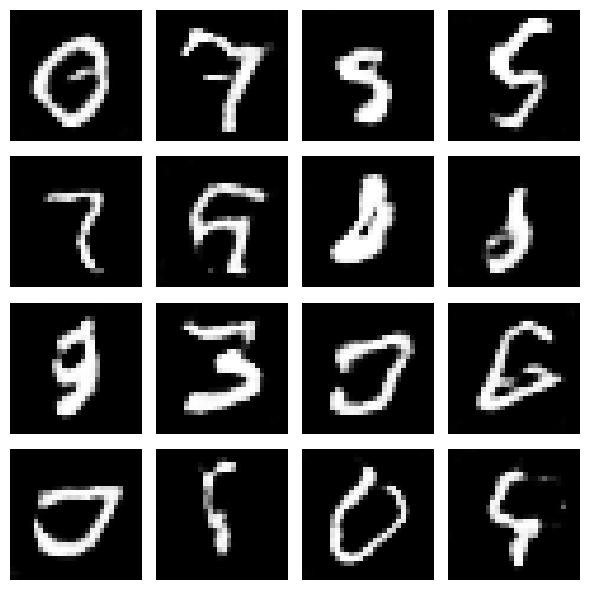

In [7]:
generator.eval()

with torch.no_grad():
    sample_images = generator(fixed_noise[:16]).cpu()

sample_images = (sample_images + 1) / 2

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flatten(), sample_images):
    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
checkpoint = {
    "generator_state_dict": {
        key: value.detach().cpu()
        for key, value in generator.state_dict().items()
    },
    "latent_dim": latent_dim,
    "image_size": 28,
    "image_channels": 1,
}

torch.save(checkpoint, "mnist_gan_generator.pth")
print("Saved: mnist_gan_generator.pth")

from google.colab import files
files.download("mnist_gan_generator.pth")

Saved: mnist_gan_generator.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>